In [4]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("../data/Processed_UICLibraryData.csv")
df

,date,time,floor,occupancy_count,noise_level,notes
0,9/21/2026,4pm,first,53,Quiet,Normal
1,9/21/2026,4pm,second,387,Noisy,High movement
2,9/22/2026,4pm,first,48,Quiet,Normal
3,9/22/2026,4pm,second,422,Noisy,High movement
4,9/23/2026,4pm,first,58,Quiet,Normal
5,9/23/2026,4pm,second,405,Noisy,High movement
6,9/24/2026,4pm,first,49,Quiet,Normal
7,9/24/2026,4pm,second,365,Moderate,High movement
8,9/25/2026,4pm,first,32,Quiet,Lower than usual
9,9/25/2026,4pm,second,285,Moderate,Lower than usual


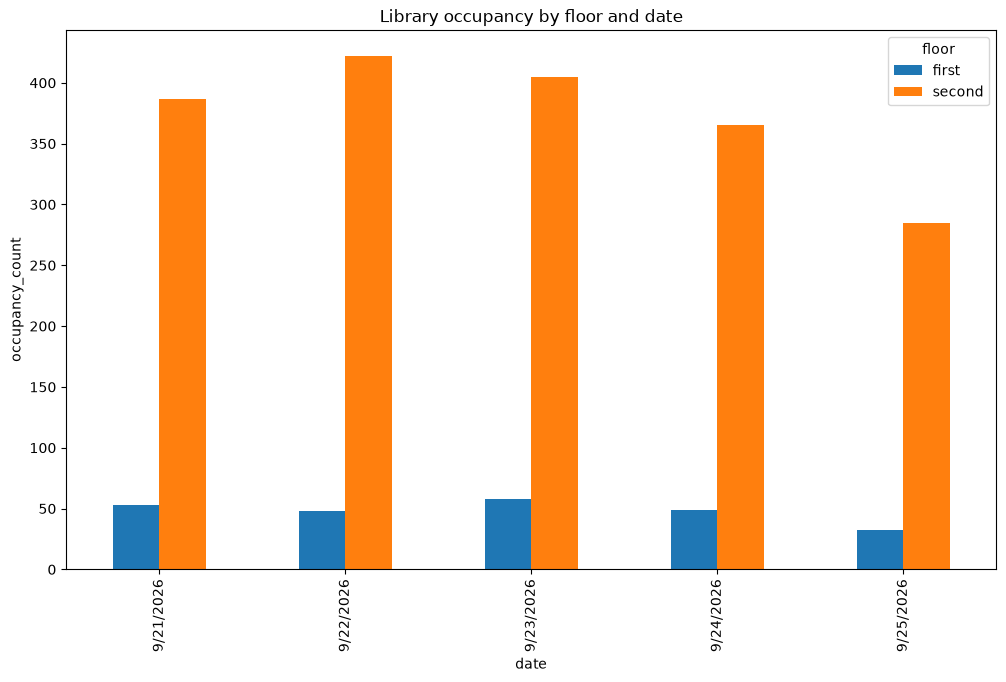

In [ ]:
pivot = df.pivot(
    index="date",
    columns="floor",
    values="occupancy_count"
)

pivot.plot(kind="bar", figsize=(12, 8))

plt.xlabel("date")
plt.ylabel("occupancy_count")
plt.title("Library occupancy by floor and date")
plt.show()

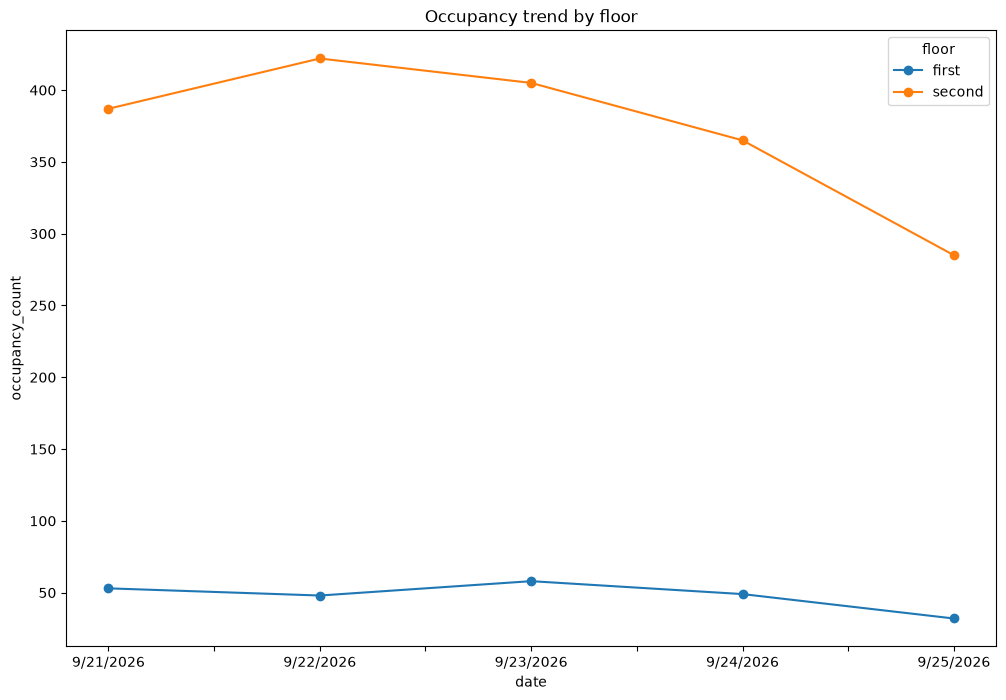

In [7]:
pivot.plot(kind="line", marker="o", figsize=(12, 8))

plt.xlabel("date")
plt.ylabel("occupancy_count")
plt.title("Occupancy trend by floor")
plt.show()

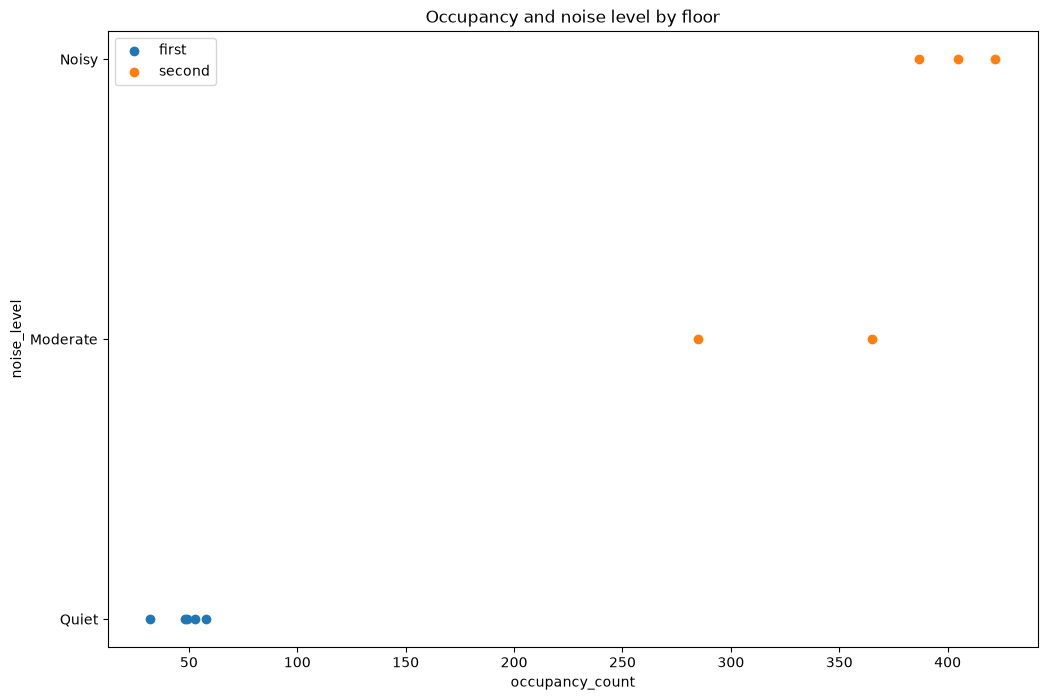

In [9]:
noise_mapping = {"Quiet": 0, "Moderate": 1, "Noisy": 2}

df["noise_num"] = df["noise_level"].map(noise_mapping)
plt.figure(figsize=(12, 8))

for floor in df["floor"].unique():
    temp = df[df["floor"] == floor]
    plt.scatter(temp["occupancy_count"], temp["noise_num"], label=floor)

plt.yticks([0, 1, 2], ["Quiet", "Moderate", "Noisy"])
plt.xlabel("occupancy_count")
plt.ylabel("noise_level")
plt.title("Occupancy and noise level by floor")
plt.legend()
plt.show()